# Evaluation

## Load dataset and model

In [25]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = False
rgb = False

# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])


from TimeSformer.VDT_cat_vm import VDT_cat
from DDIM.ddim import remove_module_prefix
nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 200
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False



cuda:0
metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
metadata exists in: dataset/2024-10-31_xacti_5fps/test/metadata_40.pkl


## Evaluate one single real data's Manhattan distance with other data in the dataset

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
import random

dec_vid_list = []
rec_mot_list = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)
idx=475
batch, vid_idx, path = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

dec_vid_list.append(batch)
rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


# 随机抽取 n 个索引
random_indices = random.sample(range(len(valid_dataset)), 50)

# 从数据集中抽取数据
for idx in random_indices:
    batch, vid_idx, path = valid_dataset[idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

    dec_vid_list.append(batch)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))



metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl


In [35]:
from eval.utils import manhattan_dist
frame_t = 10 

manhattan_distance = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim)
torch.save(manhattan_distance, 'eval/manhattan_distances.pt')


Frame 1 Manhattan Distances: {'undetected_obs': tensor(0.3097), 'ceiling': tensor(0.1751), 'wall': tensor(0.2049), 'detected_furniture': tensor(0.0460), 'door': tensor(0.0058), 'Human': tensor(0.0176), 'Floor': tensor(0.1636)}
Frame 2 Manhattan Distances: {'undetected_obs': tensor(0.2649), 'ceiling': tensor(0.1887), 'wall': tensor(0.2138), 'detected_furniture': tensor(0.0464), 'door': tensor(0.0058), 'Human': tensor(0.0111), 'Floor': tensor(0.1658)}
Frame 3 Manhattan Distances: {'undetected_obs': tensor(0.3561), 'ceiling': tensor(0.1850), 'wall': tensor(0.1557), 'detected_furniture': tensor(0.0101), 'door': tensor(0.0073), 'Human': tensor(0.0316), 'Floor': tensor(0.1747)}
Frame 4 Manhattan Distances: {'undetected_obs': tensor(0.2848), 'ceiling': tensor(0.1622), 'wall': tensor(0.1713), 'detected_furniture': tensor(0.0559), 'door': tensor(0.0043), 'Human': tensor(0.0112), 'Floor': tensor(0.1715)}
Frame 5 Manhattan Distances: {'undetected_obs': tensor(0.2712), 'ceiling': tensor(0.1487), '

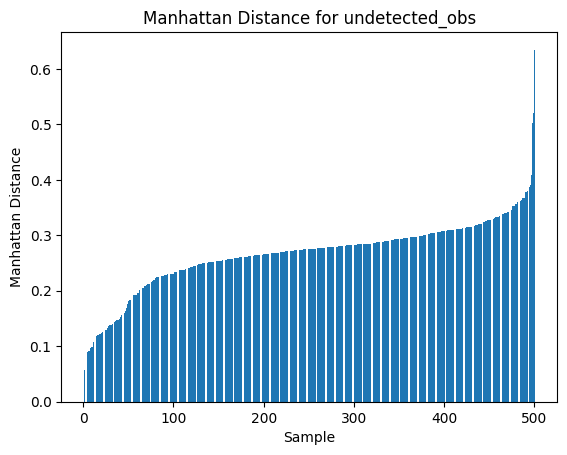

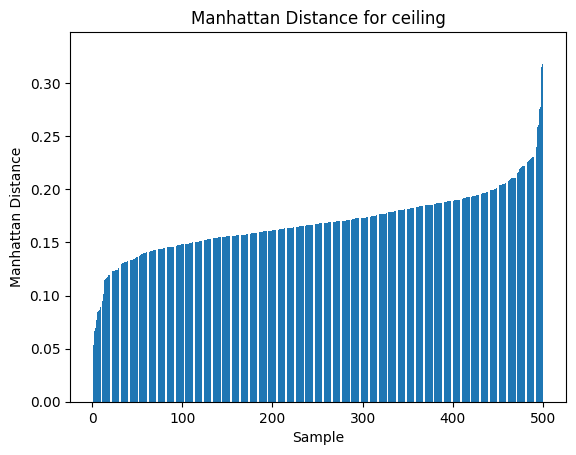

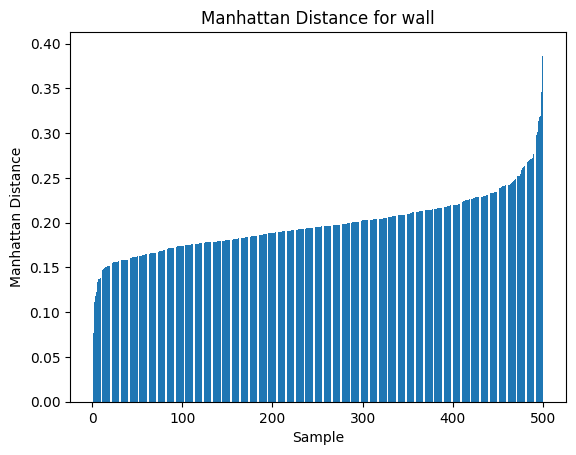

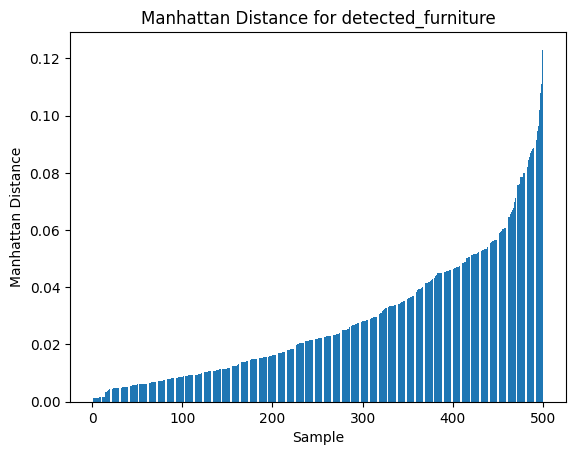

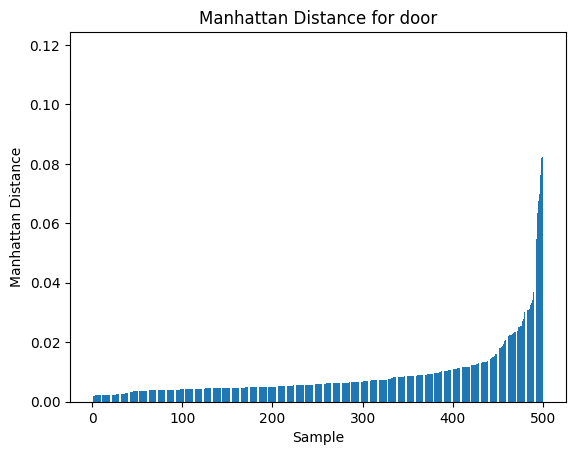

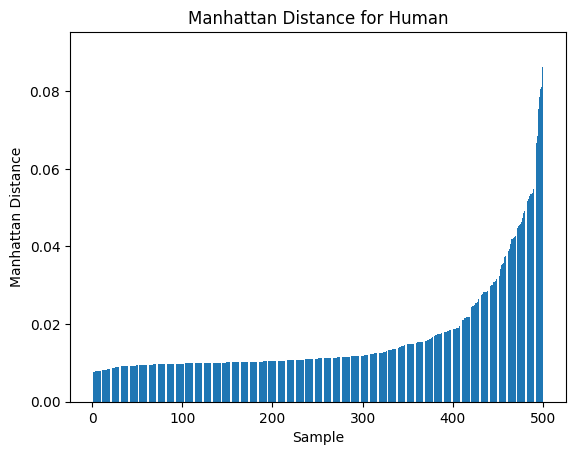

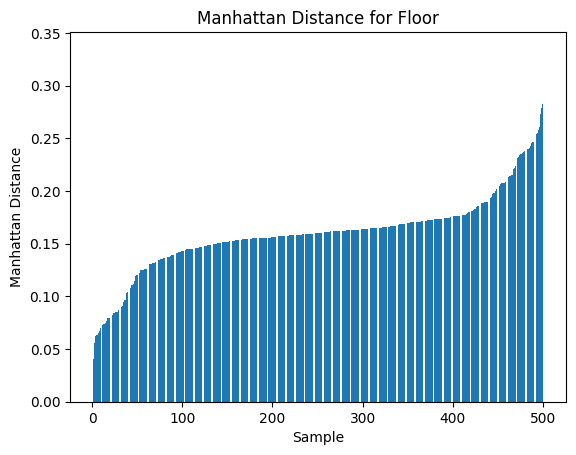

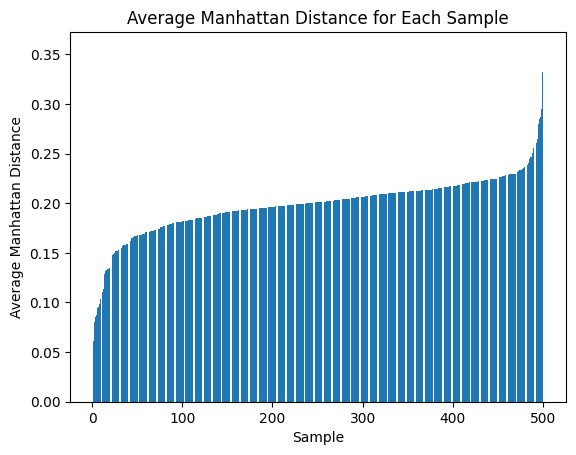

In [36]:
from eval.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval/manhattan_distances.pt')
visual_MD(distances)

## Evaluate multiple real data's Manhattan distances and calculate the average

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
import random
from eval.utils import manhattan_dist

all_manhattan_distance = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 500)
for real_idx in real_data_random_indices:
    dec_vid_list = []
    rec_mot_list = []

    batch, vid_idx, path = valid_dataset[real_idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

    dec_vid_list.append(batch)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


    # 随机抽取 100 个索引
    random_indices = random.sample(range(len(valid_dataset)), 50)

    # 从数据集中抽取数据
    for idx in random_indices:
        batch, vid_idx, path = valid_dataset[idx]
        batch, mot = dict.values(batch)
        mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

        dec_vid_list.append(batch)
        rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))

    frame_t = 10 
    manhattan_distance = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim)
    all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval/all_manhattan_distances.pt')



In [8]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval/all_manhattan_distances_500x50.pt')

# 初始化字典以存储排序后的结果
sorted_distances = []

# 遍历所有曼哈顿距离，按 channel 的值从小到大排序每个样本
for distances in all_distances:
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        sorted_sample_distances[sample] = {channel: torch.tensor(value.item()) for channel, value in sorted(distance.items(), key=lambda item: item[1])}
    sorted_distances.append(sorted_sample_distances)

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in all_distances[0][f'Sample 1'].keys()} for i in range(50)}
# 将结果存储为字典
torch.save(sorted_distances, 'eval/sorted_manhattan_distances.pt')

all_distances = torch.load('eval/sorted_manhattan_distances.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_distances:
    for t, distance in distances.items():
        for channel, dist in distance.items():
            average_distances[t][channel] += dist.item()

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval/average_manhattan_distances.pt')

Average Manhattan Distances for Each Sample:
Sample 1: {'undetected_obs': tensor(0.2514), 'ceiling': tensor(0.1459), 'wall': tensor(0.1567), 'detected_furniture': tensor(0.0500), 'door': tensor(0.0156), 'Human': tensor(0.0193), 'Floor': tensor(0.1245)}
Sample 2: {'undetected_obs': tensor(0.2510), 'ceiling': tensor(0.1460), 'wall': tensor(0.1563), 'detected_furniture': tensor(0.0481), 'door': tensor(0.0156), 'Human': tensor(0.0201), 'Floor': tensor(0.1250)}
Sample 3: {'undetected_obs': tensor(0.2484), 'ceiling': tensor(0.1443), 'wall': tensor(0.1568), 'detected_furniture': tensor(0.0498), 'door': tensor(0.0156), 'Human': tensor(0.0188), 'Floor': tensor(0.1244)}
Sample 4: {'undetected_obs': tensor(0.2556), 'ceiling': tensor(0.1494), 'wall': tensor(0.1581), 'detected_furniture': tensor(0.0488), 'door': tensor(0.0155), 'Human': tensor(0.0197), 'Floor': tensor(0.1287)}
Sample 5: {'undetected_obs': tensor(0.2513), 'ceiling': tensor(0.1457), 'wall': tensor(0.1542), 'detected_furniture': tenso

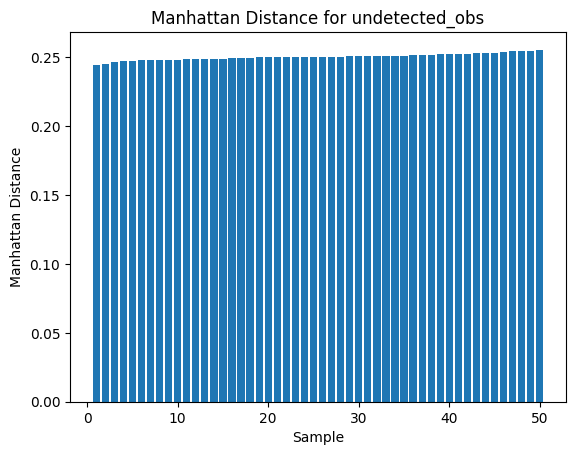

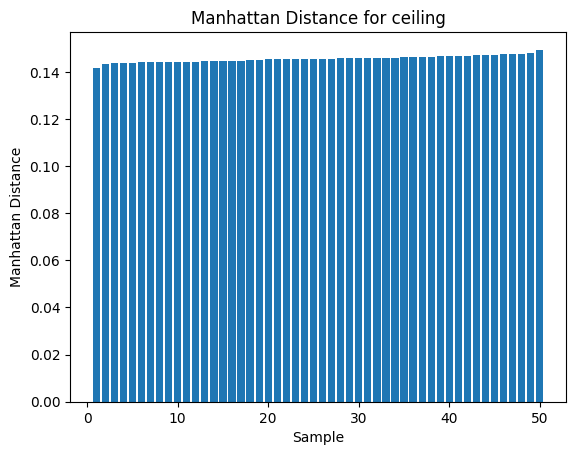

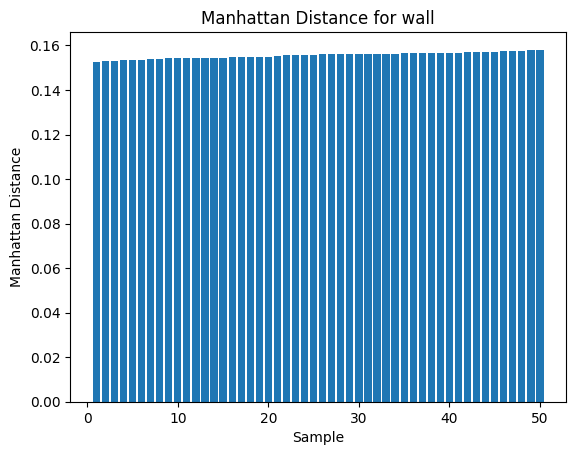

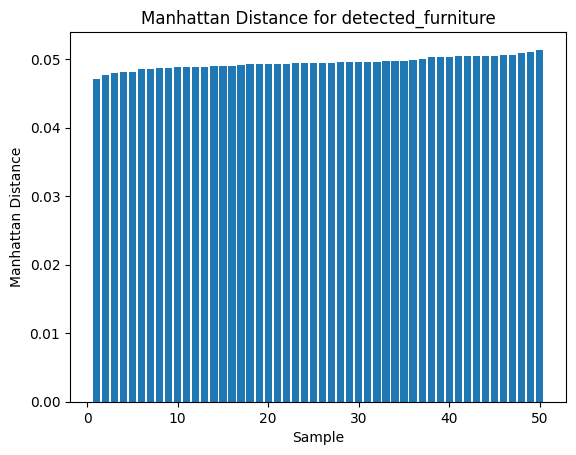

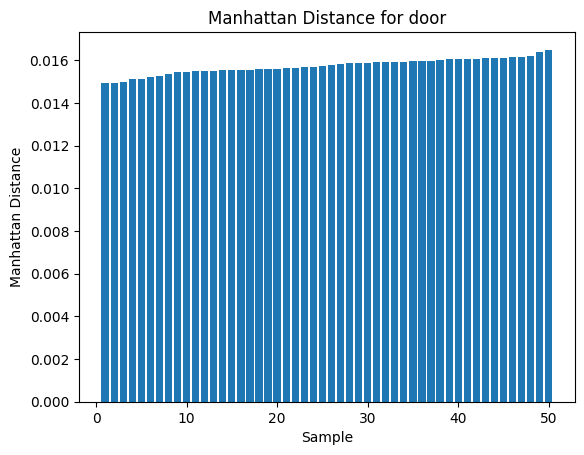

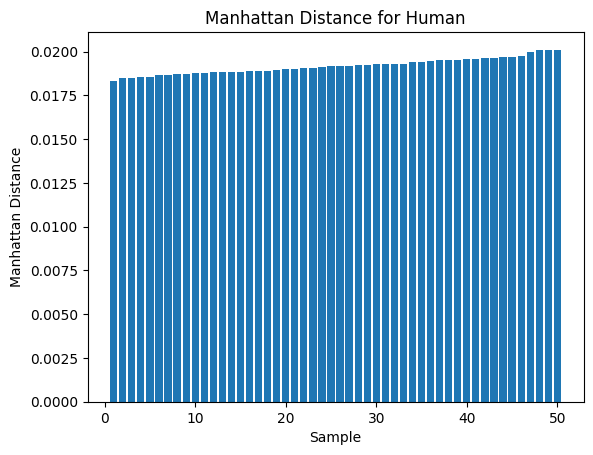

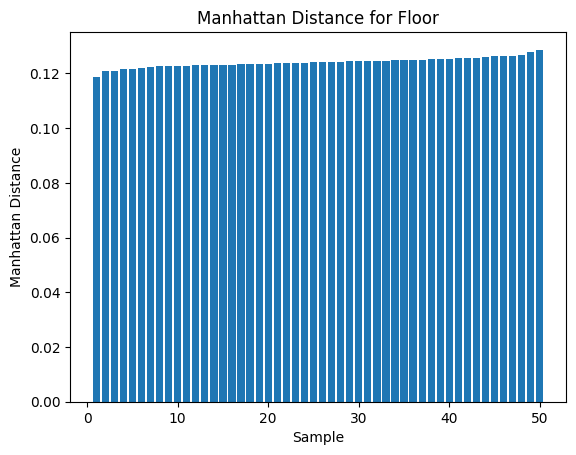

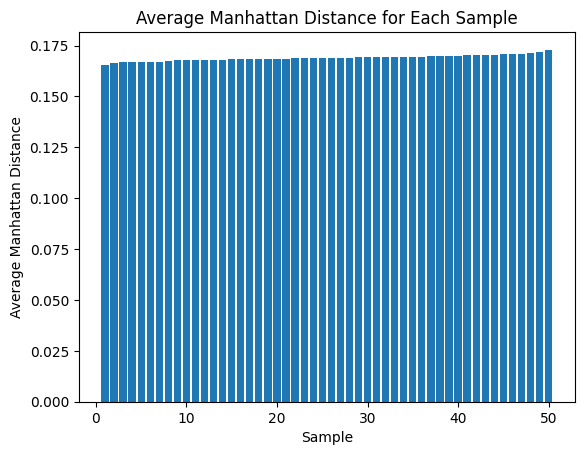

In [9]:
from eval.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval/average_manhattan_distances.pt')
visual_MD(distances)

## Evaluate generated data on time axis

load model: success
metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
731 dataset/2024-10-31_xacti_5fps/train/data_2024-10-24-16_54_21_3m_in_233_sec/18.mp4
li:0.000 ang:0.000
li:0.000 ang:0.100
li:0.007 ang:0.200
li:0.007 ang:0.100
li:0.035 ang:0.100
li:0.189 ang:0.000
li:0.280 ang:0.000
li:0.217 ang:-0.300
li:0.238 ang:-0.300
li:0.287 ang:-0.200
li:0.266 ang:0.000
li:0.294 ang:0.100
li:0.322 ang:0.100
li:0.231 ang:0.000
li:0.301 ang:0.100
li:0.210 ang:0.100
li:0.238 ang:0.300
li:0.266 ang:0.300
li:0.259 ang:0.200
li:0.245 ang:0.300
li:0.315 ang:0.000
li:0.231 ang:-0.100
li:0.238 ang:-0.100
li:0.294 ang:0.000
li:0.259 ang:-0.100
li:0.266 ang:0.000
li:0.350 ang:-0.100
li:0.224 ang:0.000
li:0.217 ang:0.000
li:0.259 ang:0.000
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 6

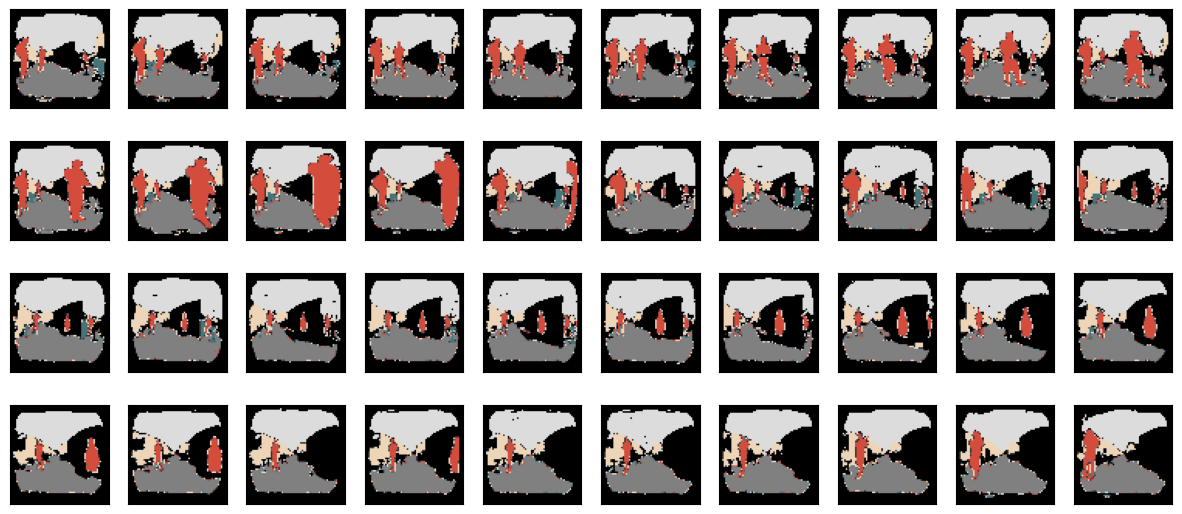

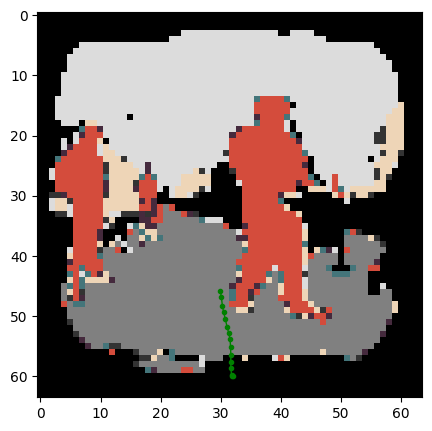

In [26]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

idx=13350
# Pick a sample in the dataset
# memo: 20241031_data 475, 8000, 12318, 12949, 13180, 13344, 13350, 14000, 16000, 18500, 19206
# memo: 20241031_test_data 800, 3000, 3335
r = 3
vis_id = 0 # the index for visualization, default = 0
pred_num = 100 # The number of multiple predictions
frame_t = 10 

test = True
batch, vid_idx, path = valid_dataset[idx]
print(vid_idx, path)
batch, mot = dict.values(batch)

mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
start_time = time.time()

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_vid_list = []
rec_mot_list = []
dec_vid_list = []

################ Original image #############################
batch = batch.permute(0,3,1,2)
dec_vid_list.append(batch.permute(0,2,3,1))
rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))
if rgb:
    batch_rgb = batch
else:
    batch_rgb = gray2color(batch)
    batch_rgb = torch.clamp(batch_rgb, 0,1)

    
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

if test:
    diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
    diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

# Choose a mask type from 0 to 2
# 0: prediction 1: backward 2: interpolation, t means the current frame
mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

##################### Mask the video or not ##############################
# mask_vid = torch.zeros_like(diff_a)
###########################################################################
##################### Mask the motion or not ##############################
# mask_motion = torch.zeros_like(diff_b)
# b = torch.tensor([[0.3,-0.]])
# b = b.repeat(1,args.sequence_length,1).repeat(pred_num,1,1).to(DEVICE)
###########################################################################

a = a.repeat(pred_num,1,1,1,1)
b = b.repeat(pred_num,1,1)
diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

with torch.no_grad():
    rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
    
rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)
est_time = time.time() - start_time

################ Decode image #############################
for i in range(pred_num):  
    rec_mot_list.append(rec_mot[i]) 
    # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
    dec_vid = vae.decode(rec_vid[i]).sample
    dec_vid_list.append(dec_vid.permute(0,2,3,1))
    print(dec_vid.permute(0,2,3,1).shape)
    if rgb:
        dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
    else:
        dec_rgb = gray2color(dec_vid)
        dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    rec_vid_list.append(dec_rgb)

print("estimate time:", est_time)

In [27]:
from eval.utils import manhattan_dist
manhattan_distance = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, mean=False)


Frame 1 Manhattan Distances: {'undetected_obs': tensor([0.0747, 0.0813, 0.0964, 0.1340, 0.1143, 0.1389, 0.1587, 0.1184, 0.1243,
        0.1421, 0.1357, 0.1431, 0.1885, 0.1633, 0.2036, 0.1897, 0.2129, 0.2124,
        0.2151, 0.1960, 0.2161, 0.1995, 0.2368, 0.1846, 0.2122, 0.2170, 0.2163,
        0.2100, 0.2168, 0.2178]), 'ceiling': tensor([0.1260, 0.1799, 0.1724, 0.1814, 0.1780, 0.1917, 0.1912, 0.1777, 0.1746,
        0.1790, 0.2075, 0.1948, 0.2144, 0.2051, 0.2131, 0.2129, 0.2041, 0.2070,
        0.1794, 0.1797, 0.1768, 0.1885, 0.1870, 0.1782, 0.1868, 0.1724, 0.1799,
        0.1741, 0.1853, 0.1960]), 'wall': tensor([0.0286, 0.0352, 0.0286, 0.0383, 0.0378, 0.0432, 0.0408, 0.0396, 0.0427,
        0.0669, 0.0579, 0.0557, 0.0642, 0.0544, 0.0571, 0.0496, 0.0486, 0.0593,
        0.0535, 0.0718, 0.0698, 0.0771, 0.0688, 0.0835, 0.0737, 0.0730, 0.0769,
        0.0796, 0.0767, 0.0496]), 'detected_furniture': tensor([0.0186, 0.0151, 0.0154, 0.0171, 0.0283, 0.0156, 0.0254, 0.0278, 0.0251,
        0

In [28]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns


# 读取 .pt 文件
distances = manhattan_distance

# 定义 channel 名称和颜色
# channels = ['undetected_obs', 'ceiling', 'wall', 'detected_furniture', 'door', 'Human', 'Floor']
channels = ['Human','ceiling', 'wall','Floor']

colors = sns.color_palette("Set2", n_colors=8)

# 提取每个 channel 的曼哈顿距离
channel_distances = {channel: [] for channel in channels}

for sample, distance in distances.items():
    for channel in channels:
        channel_distances[channel].append(distance[channel].tolist())


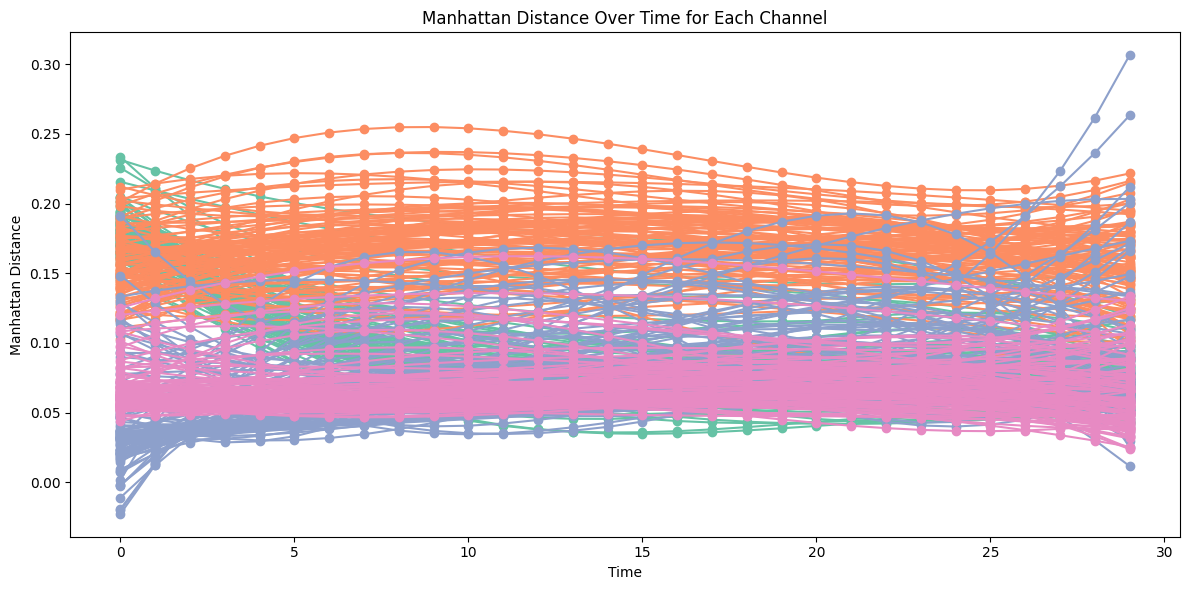

In [29]:
from sklearn.cluster import KMeans


# 设置时间间距
time_interval = 1

# 设置分组数量
n_clusters = 100

# 绘制拟合曲线
plt.figure(figsize=(12, 6))

for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T

    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data) * time_interval, time_interval)

    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]

        # 拟合每组数据
        group_mean = np.mean(group, axis=1)
        poly = np.poly1d(np.polyfit(time_points, group_mean, 3))

        # 绘制数据点和拟合曲线
        # plt.plot(time_points, group_mean, 'o', label=f'{channel} Group {cluster + 1} Data', color=color)
        plt.plot(time_points, poly(time_points), 'o-', label=f'{channel} Group {cluster + 1} Fit', color=color)

plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
plt.title('Manhattan Distance Over Time for Each Channel')
# plt.legend()
plt.tight_layout()
plt.show()

(30, 100)
<module 'time' (built-in)>
(30, 87) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 13) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 42) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 58) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 100)
<module 'time' (built-in)>
(30, 74) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 26) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 15) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 85) (0.4, 0.7607843137254902, 0.6470588235294118)


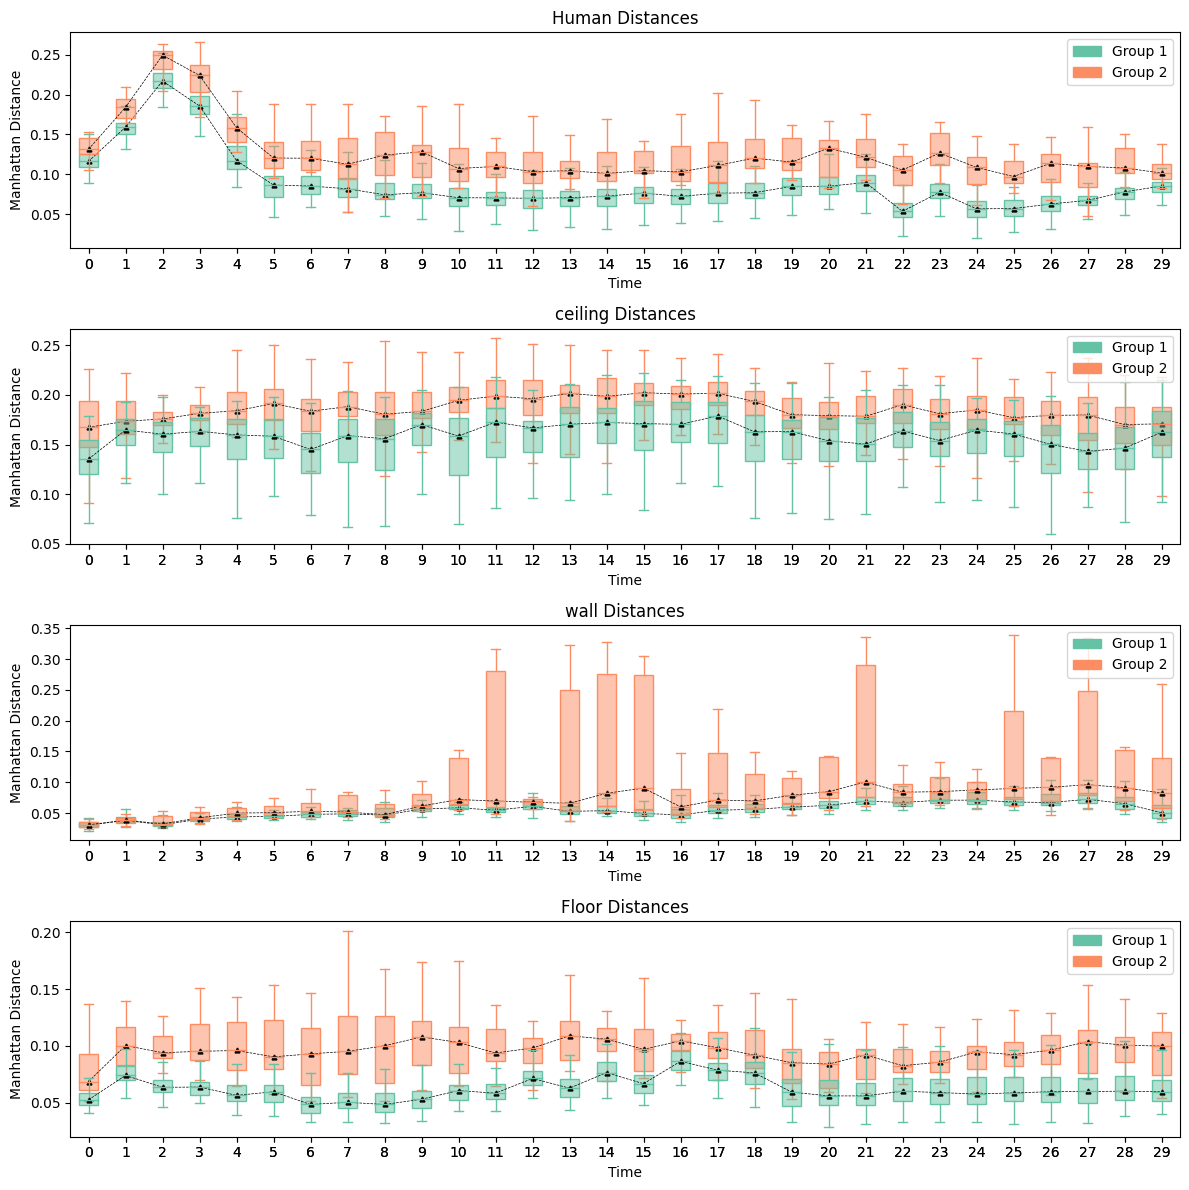

In [30]:
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors

# 设置时间间距
time_interval = 1

# 设置分组数量
n_clusters = 2
# 绘制箱形图
plt.figure(figsize=(12, 12))

for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T
    print(data.shape)
    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data) * time_interval, time_interval)
    print(time)
    plt.subplot(len(channels), 1, i + 1)
    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]
        color_idx = colors[cluster % len(colors)]
        if group.shape[1] > 50:
            color_idx = colors[0]
        else:
            color_idx = colors[1]

        # 设置透明度
        facecolor = mcolors.to_rgba(color_idx, alpha=0.5)
        edgecolor = mcolors.to_rgba(color_idx, alpha=1.0)
        # 绘制箱形图
        data_to_plot = [group[t] for t in range(len(group))]
        box = plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                    boxprops=dict(facecolor=facecolor, color=edgecolor),
                    medianprops=dict(color=edgecolor),
                    whiskerprops=dict(color=edgecolor),
                    capprops=dict(color=edgecolor),
                    showfliers=False,
                    widths=0.5)
        print(group.shape,color_idx)
        # 提取中位数值并连线
        medians = [item.get_ydata()[0] for item in box['medians']]
        plt.plot(time_points, medians, color='black', linestyle='--', linewidth=0.5, marker='^',markersize=3.5)


    plt.xlabel('Time')
    plt.ylabel('Manhattan Distance')
    plt.title(f'{channel} Distances')
    # plt.xticks(np.arange(0, len(data), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
    # 创建图例条目
    legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
    plt.legend(handles=legend_patches, loc='upper right')

plt.tight_layout()
plt.show()


(30, 97)
(30, 3)


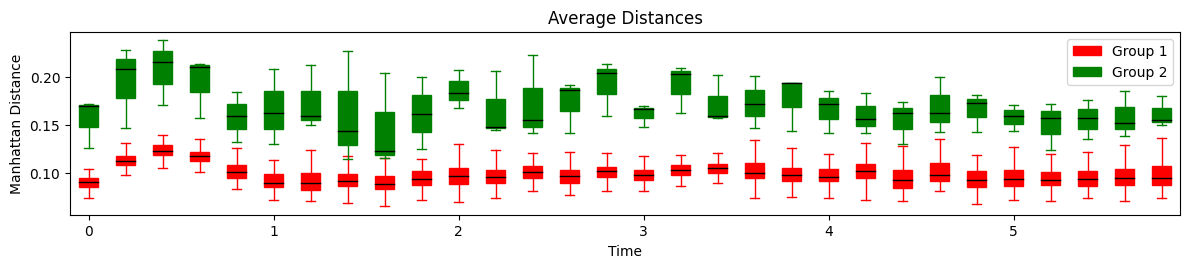

In [ ]:
plt.figure(figsize=(12, 12))

#  计算所有 channel 的平均曼哈顿距离
average_distances = np.mean([np.array(channel_distances[channel]) for channel in channels], axis=0).T

# 使用 KMeans 将平均数据分成 n_clusters 组
kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(average_distances.T)
labels = kmeans.labels_

# 计算时间点
time_points = np.arange(0, len(average_distances) * time_interval, time_interval)

plt.subplot(len(channels) + 1, 1, 1)
for cluster in range(n_clusters):
    # 分别提取每组数据
    group = average_distances[:, labels == cluster]
    print(group.shape)
    # 绘制箱形图
    data_to_plot = [group[t] for t in range(len(group))]
    plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                boxprops=dict(facecolor=colors[cluster % len(colors)], color=colors[cluster % len(colors)]),
                medianprops=dict(color='black'),
                whiskerprops=dict(color=colors[cluster % len(colors)]),
                capprops=dict(color=colors[cluster % len(colors)]),
                showfliers=False,
                widths=0.5)

plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
plt.title('Average Distances')
plt.xticks(np.arange(0, len(average_distances), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
# 创建图例条目
legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
plt.legend(handles=legend_patches, loc='upper right')

plt.tight_layout()
plt.show()
